# Análise exploratória: churn de clientes de um banco

Primeira etapa do projeto: entender os dados e as variáveis que se relacionam com o churn. O dataset tratado gerado aqui é usado no notebook `02_modelagem`.

# Sobre o dataset

Abaixo está o mapeamento e a descrição de cada um dos atributos presentes no conjunto de dados:

- `RowNumber` (Numérico): Corresponde ao número do registro (linha).

- `CustomerId` (Numérico): Identificador único do cliente.

- `Surname` (Texto): Sobrenome do cliente.

- `CreditScore` (Numérico): Pontuação de crédito do cliente.

- `Geography` (Categórico): Localização geográfica do cliente.

- `Gender` (Categórico): Gênero do cliente.

- `Age` (Numérico): Idade do cliente.

- `Tenure` (Numérico): Número de anos que o cliente está com o banco.

- `Balance` (Numérico): Saldo bancário do cliente.

- `NumOfProducts` (Numérico): Quantidade de produtos que o cliente adquiriu ou utiliza no banco.

- `HasCrCard` (Binário): Indica se o cliente possui ou não cartão de crédito.

- `IsActiveMember` (Binário): Indica se o cliente é um membro ativo no banco.

- `EstimatedSalary` (Numérico): Salário estimado do cliente.

- `Complain` (Binário): Indica se o cliente fez uma reclamação.

- `Satisfaction Score` (Numérico): Pontuação de satisfação dada pelo cliente em relação à resolução de sua reclamação.

- `Card Type` (Categórico): Tipo de cartão que o cliente possui (ex: Gold, Platinum, Diamond).

- `Point Earned` (Numérico): Pontos acumulados pelo cliente ao utilizar o cartão de crédito.

- `Exited` (Binário): Variável Alvo (Target). Indica se o cliente deixou o banco (1) ou continuou ativo (0).

# Conhecendo os dados

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # permite importar o pacote src a partir da pasta notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

from src.config import RANDOM_STATE, DADOS_BRUTOS, DADOS_TRATADOS, PASTA_FIGURAS
from src.visualizacao import (
    aplicar_tema, k_formatter, rotular_barras, linha_referencia, barras_100,
    COR_PRINCIPAL, COR_REFERENCIA, PALETA_CHURN, LEGENDA_CHURN, PALETA_CATEGORIAS, CMAP_CORRELACAO,
)

np.random.seed(RANDOM_STATE)
aplicar_tema()   # padrão visual único para todas as figuras (cores e funções de gráfico ficam em src/visualizacao.py)

In [2]:
df = pd.read_csv(DADOS_BRUTOS)
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0,0,1,DIAMOND,300
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0,0,5,PLATINUM,771
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1,1,3,SILVER,564
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1,1,2,GOLD,339


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  str    
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  str    
 5   Gender              10000 non-null  str    
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card Type       

In [4]:
df.duplicated().sum() # Verificando se há duplicatas

np.int64(0)

In [5]:
df['CustomerId'].nunique() # Verificando se há 10k id's diferentes

10000

In [6]:
df = df.drop(columns=['RowNumber', 'CustomerId', 'Surname']) # Dropando colunas que não agregam a nossa análise
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


# Análise dos Dados

Aqui começa a parte da análise dos dados. Dividi ela em 3 etapas principais:

- Heatmap: a primeira etapa da análise é observar as correlações entre as variáveis do dataframe, principalmente entre a variável target e as restantes. Dessa forma consigo saber quais variáveis tem uma correlação linear evidente sobre as outras. Vale destacar que o heatmap tem suas limitações, mas dependendo dos resultados posso gerar insights logo no início da EDA e posteriormente analisar de forma mais profunda essas variáveis.

- Análise Univariada: nessa parte da análise vou investigar a distribuição geral entre as variáveis, tirando informações que podem ser importantes para o resto da análise.

- Análise Bivariada: assim como no heatmap, vou observar as relações entre as variáveis, mas de forma mais aprofundada e detalhada para enfim conseguir responder algumas perguntas com insights valiosos.

## Heatmap

Vou começar com o heatmap para observar a correlação linear das variáveis.

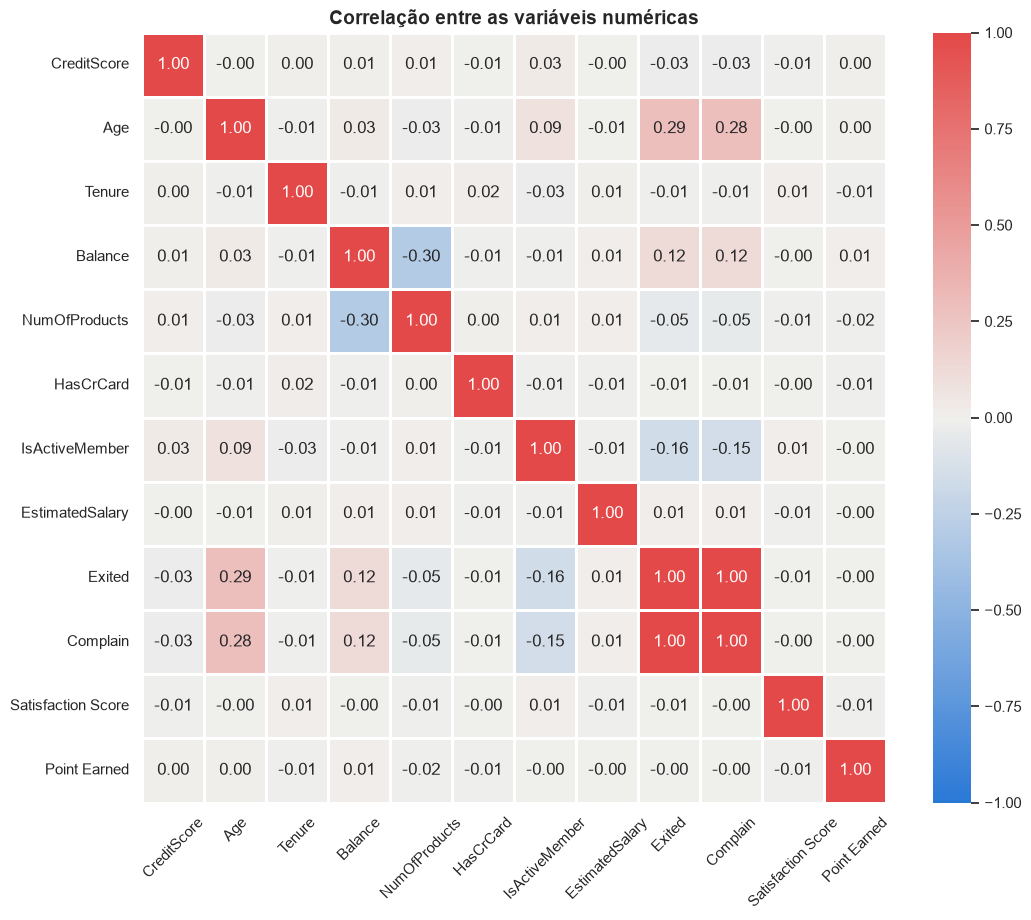

In [7]:
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, fmt='.2f',
            cmap=CMAP_CORRELACAO, vmin=-1, vmax=1, center=0, linewidths=1, linecolor='white', ax=ax)
ax.set_title('Correlação entre as variáveis numéricas')
ax.tick_params(axis='x', rotation=45)
plt.show()

A coluna `Complain` tem correlação de 0.996 com o churn (o heatmap arredonda para 1.00): quase todos os clientes que reclamaram saíram do banco. Vou conferir isso na tabela abaixo.

In [8]:
pd.crosstab(df['Complain'], df['Exited'])

Exited,0,1
Complain,,
0,7952,4
1,10,2034


Dos 2044 clientes que reclamaram, 2034 churnaram, e só 4 clientes churnaram sem reclamar. Isso é **vazamento de dados** (*data leakage*): a reclamação acontece junto com a saída do cliente, então essa informação não estaria disponível no momento de prever o churn. Por isso vou remover a coluna.

In [9]:
df = df.drop(columns=['Complain'])

As variáveis com maior correlação com a variável alvo foram:
- `Age` (idade) com 29% de correlação;
- `IsActiveMember` (se é membro ativo) com -16% de correlação. O sinal negativo indica que os clientes inativos (0) churnam mais;
- `Balance` (saldo) com 12% de correlação.

Posteriormente vou verificar de forma mais detalhada a relação dessas três variáveis com o churn.

## Análise Univariada

Nessa primeira seção de análise do notebook vou analisar a **distribuição de cada variável** no dataframe.
Dividi a análise para cada tipo de variável (categórica/contínua).

### Variáveis Categóricas

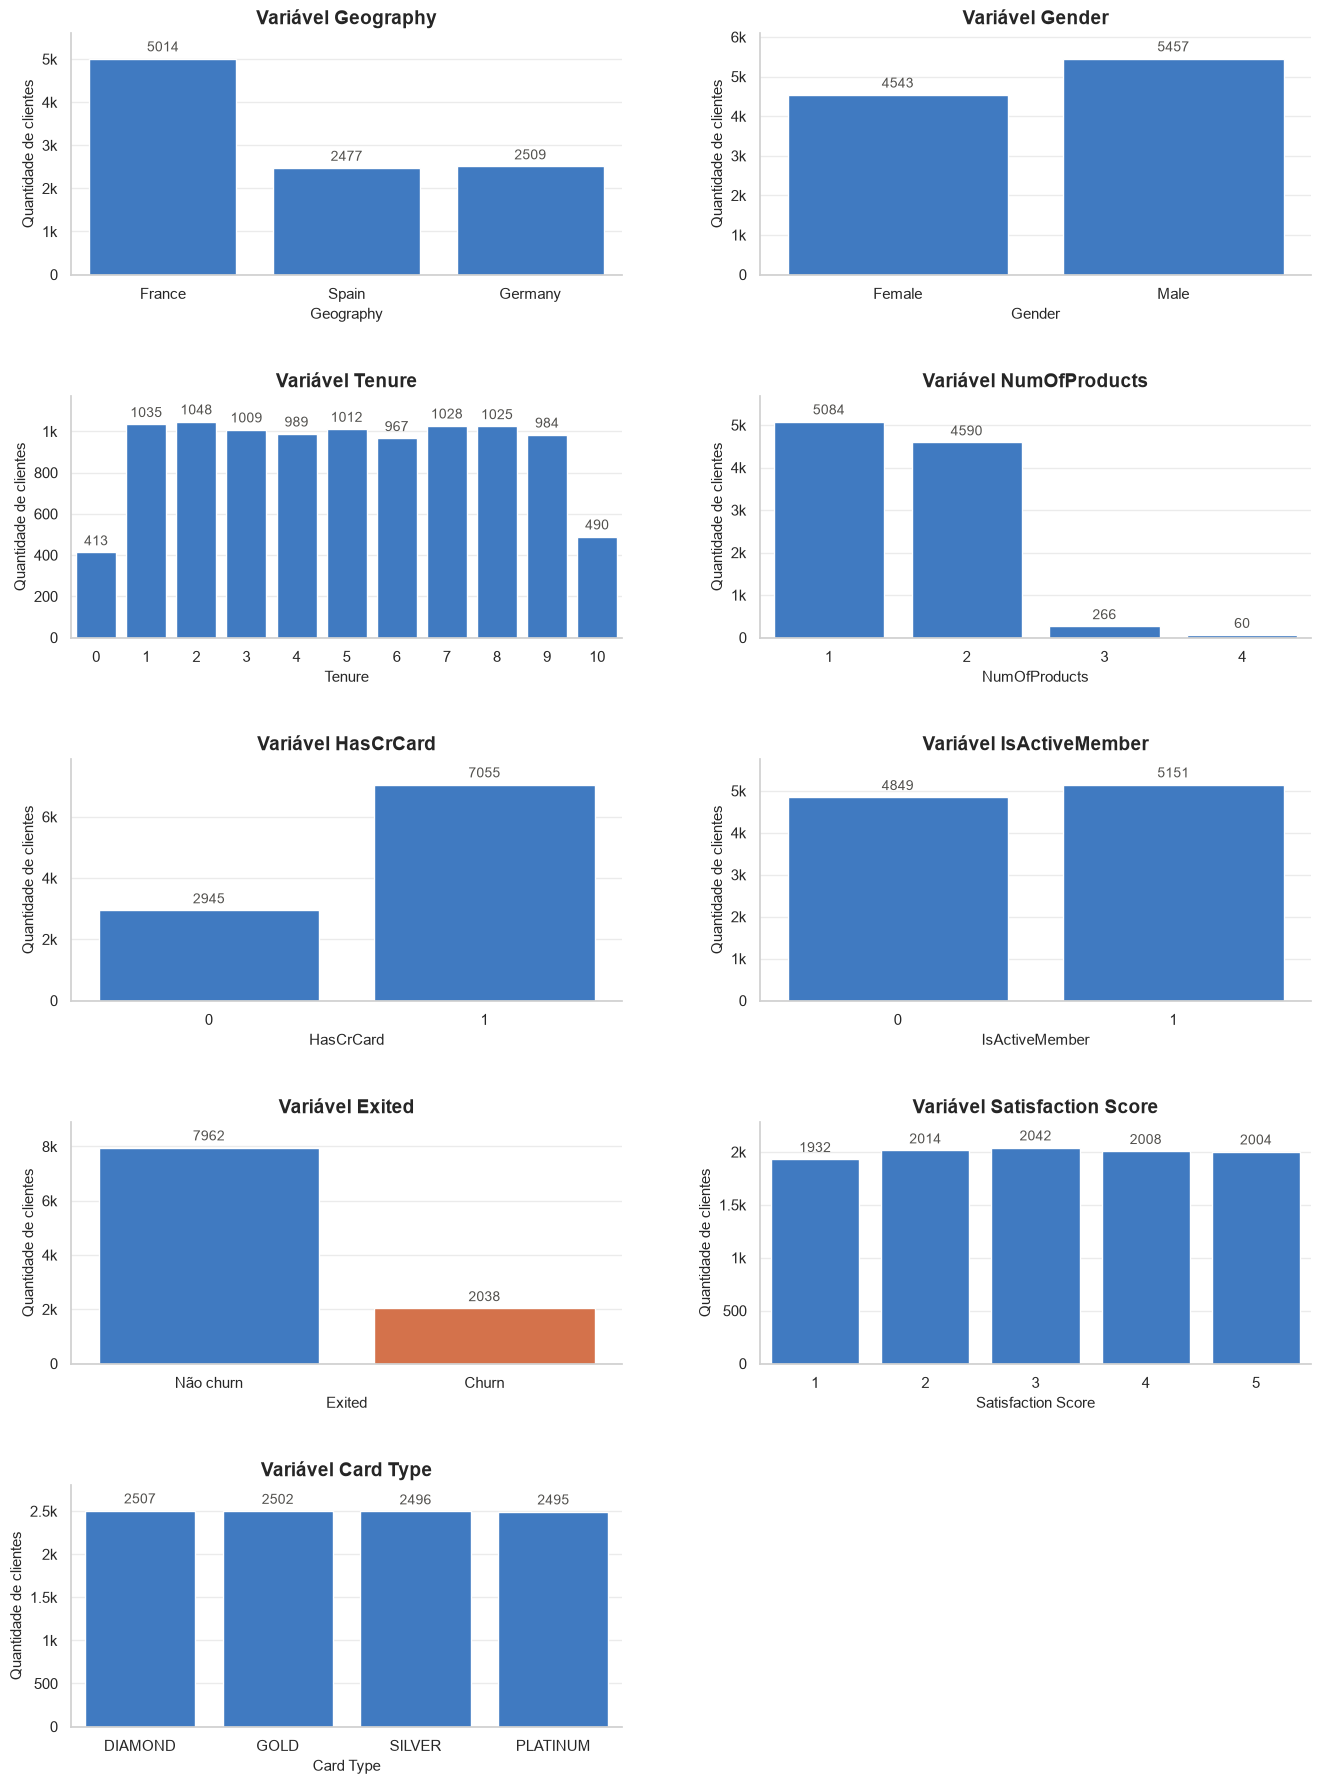

In [10]:
cols_categoricas = ['Geography', 'Gender', 'Tenure', 'NumOfProducts', 'HasCrCard',
                    'IsActiveMember', 'Exited', 'Satisfaction Score', 'Card Type']

fig, axes = plt.subplots(5, 2, figsize=(16, 22))

for ax, col in zip(axes.flat, cols_categoricas):
    if col == 'Exited':   # a target usa as cores de churn, como no resto do notebook
        sns.countplot(x=col, hue=col, data=df, palette=PALETA_CHURN, legend=False, ax=ax)
        ax.set_xticks([0, 1], LEGENDA_CHURN)
    else:
        sns.countplot(x=col, data=df, color=COR_PRINCIPAL, ax=ax)
    ax.set_title(f'Variável {col}')
    ax.set_ylabel('Quantidade de clientes')
    ax.yaxis.set_major_formatter(k_formatter)
    rotular_barras(ax)

axes.flat[-1].remove()   # 9 gráficos em uma grade 5x2: remove o espaço que sobra

plt.subplots_adjust(hspace=0.5, wspace=0.25)
plt.show()

Existem desbalanceamentos nas variáveis `NumOfProducts`, `Exited` (target), `HasCrCard` e `Geography`, Vou atrás dos valores dessas para verificar a proporção exata dessas distribuições. O restante das variáveis estão bem distribuídas.

In [11]:
df['NumOfProducts'].value_counts(normalize=True) * 100

NumOfProducts
1    50.84
2    45.90
3     2.66
4     0.60
Name: proportion, dtype: float64

In [12]:
df['Exited'].value_counts(normalize=True) * 100

Exited
0    79.62
1    20.38
Name: proportion, dtype: float64

In [13]:
df['Exited'].value_counts()

Exited
0    7962
1    2038
Name: count, dtype: int64

In [14]:
df['HasCrCard'].value_counts(normalize=True) * 100

HasCrCard
1    70.55
0    29.45
Name: proportion, dtype: float64

In [15]:
df['Geography'].value_counts(normalize=True) * 100

Geography
France     50.14
Germany    25.09
Spain      24.77
Name: proportion, dtype: float64

Resumo:
- **96.74%** das pessoas tem 1 ou 2 produtos, contra apenas **3.26%** tendo 3 ou 4.
- Cerca de **20% dos clientes** dão churn, isso representa 2038 pessoas das 10 mil pessoas.
- Cerca de **30%** das pessoas não têm cartão.
- A França representa **metade dos clientes** e engloba o dobro de pessoas comparado a Alemanha e Espanha.

Visto que a variável alvo está desbalanceada, é necessário adotar algumas estratégias para tratar disso na parte da modelagem.

### Variáveis Contínuas

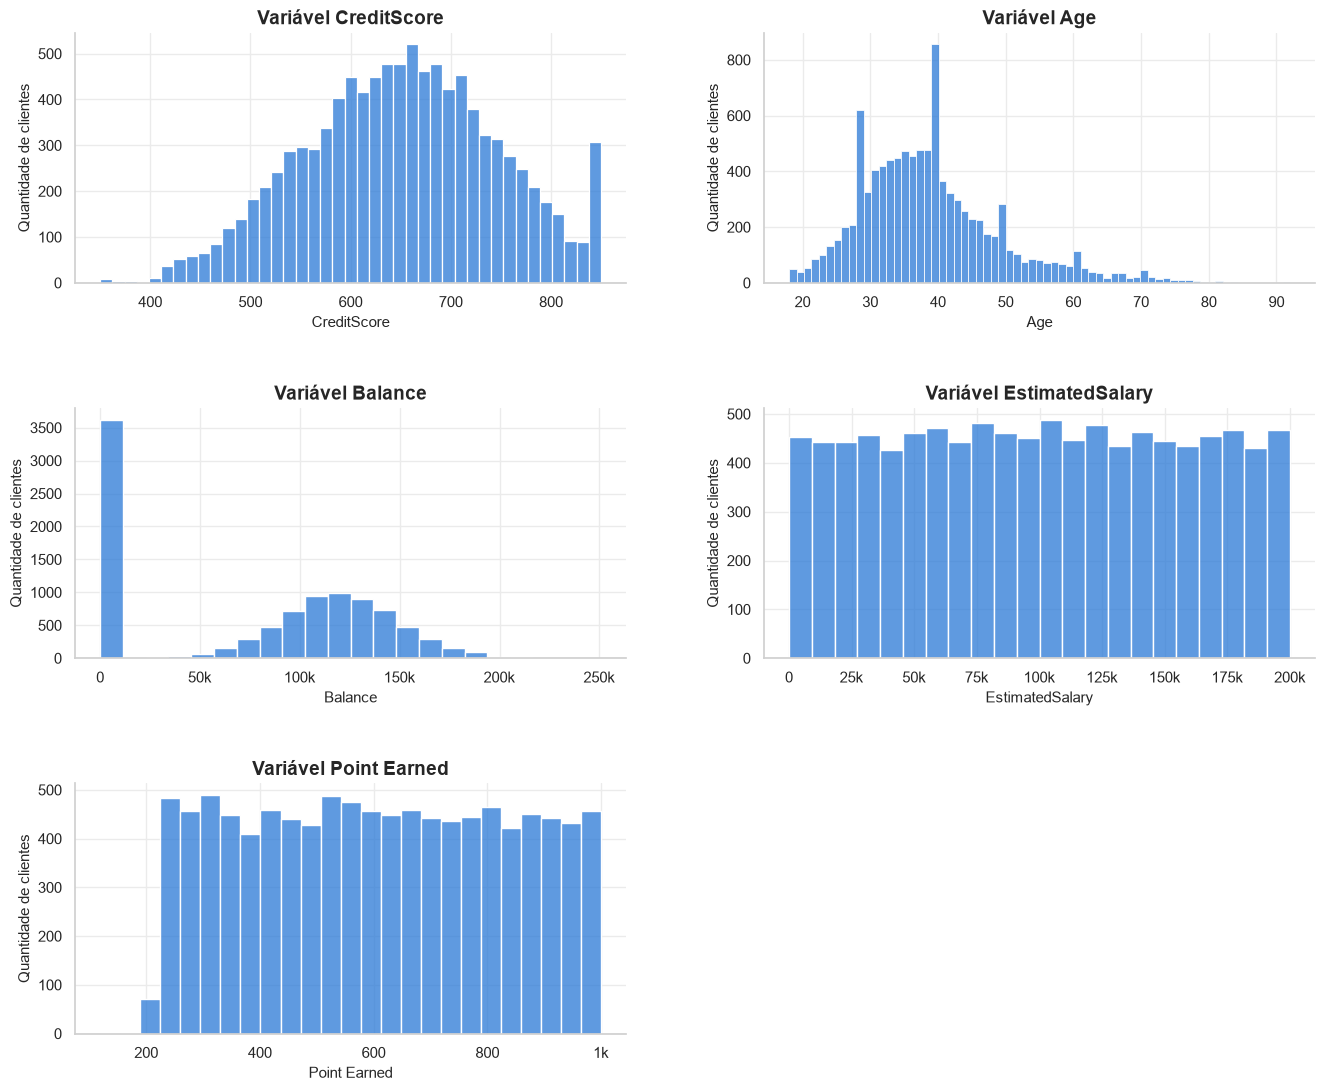

In [16]:
cols_continuas = ['CreditScore', 'Age', 'Balance', 'EstimatedSalary', 'Point Earned']

fig, axes = plt.subplots(3, 2, figsize=(16, 13))

for ax, col in zip(axes.flat, cols_continuas):
    sns.histplot(x=col, data=df, color=COR_PRINCIPAL, edgecolor='white', ax=ax)
    ax.set_title(f'Variável {col}')
    ax.set_ylabel('Quantidade de clientes')
    ax.xaxis.set_major_formatter(k_formatter)

axes.flat[-1].remove()   # 5 gráficos em uma grade 3x2: remove o espaço que sobra

plt.subplots_adjust(hspace=0.5, wspace=0.25)
plt.show()

In [17]:
q1, q3 = df['Age'].quantile([0.25, 0.75])
limite_idade = q3 + 1.5 * (q3 - q1)   # limite superior de outlier pelo critério do IQR

print(f"Age: assimetria de {df['Age'].skew():.2f}, {(df['Age'] > limite_idade).sum()} clientes acima de {limite_idade:.0f} anos")
print(f"CreditScore: {(df['CreditScore'] == 850).sum()} clientes com a pontuação máxima (850)")
print(f"Balance: {(df['Balance'] == 0).mean():.1%} dos clientes com saldo zero, mediana de {df.loc[df['Balance'] > 0, 'Balance'].median():,.0f} entre os demais")

Age: assimetria de 1.01, 359 clientes acima de 62 anos
CreditScore: 233 clientes com a pontuação máxima (850)
Balance: 36.2% dos clientes com saldo zero, mediana de 119,840 entre os demais


Insights:

- `Age` tem assimetria à direita: metade dos clientes tem entre 32 e 44 anos, com uma cauda longa até 92 anos. Os clientes acima de 62 anos são outliers pelo critério do IQR.
- `CreditScore` tem um pico no valor máximo da escala: 233 clientes com pontuação 850, provavelmente valores limitados ao teto.
- `Balance`: **36% dos clientes têm saldo zero**, e entre os demais o saldo se concentra em torno de 120 mil. São dois grupos bem diferentes misturados na mesma variável, então vou separá-los na análise bivariada.
- `EstimatedSalary` e `Point Earned` têm distribuição praticamente uniforme (todas as faixas de salário de 0 a 250 mil têm a mesma quantidade de pessoas). Isso é um sinal de dados sintéticos e torna pouco provável que essas variáveis expliquem o churn.

## Análise Bivariada

Nessa seção vou comparar as variáveis com a target e tentar encontrar padrões, diferenças e indicadores de churn.

### Variáveis Categóricas

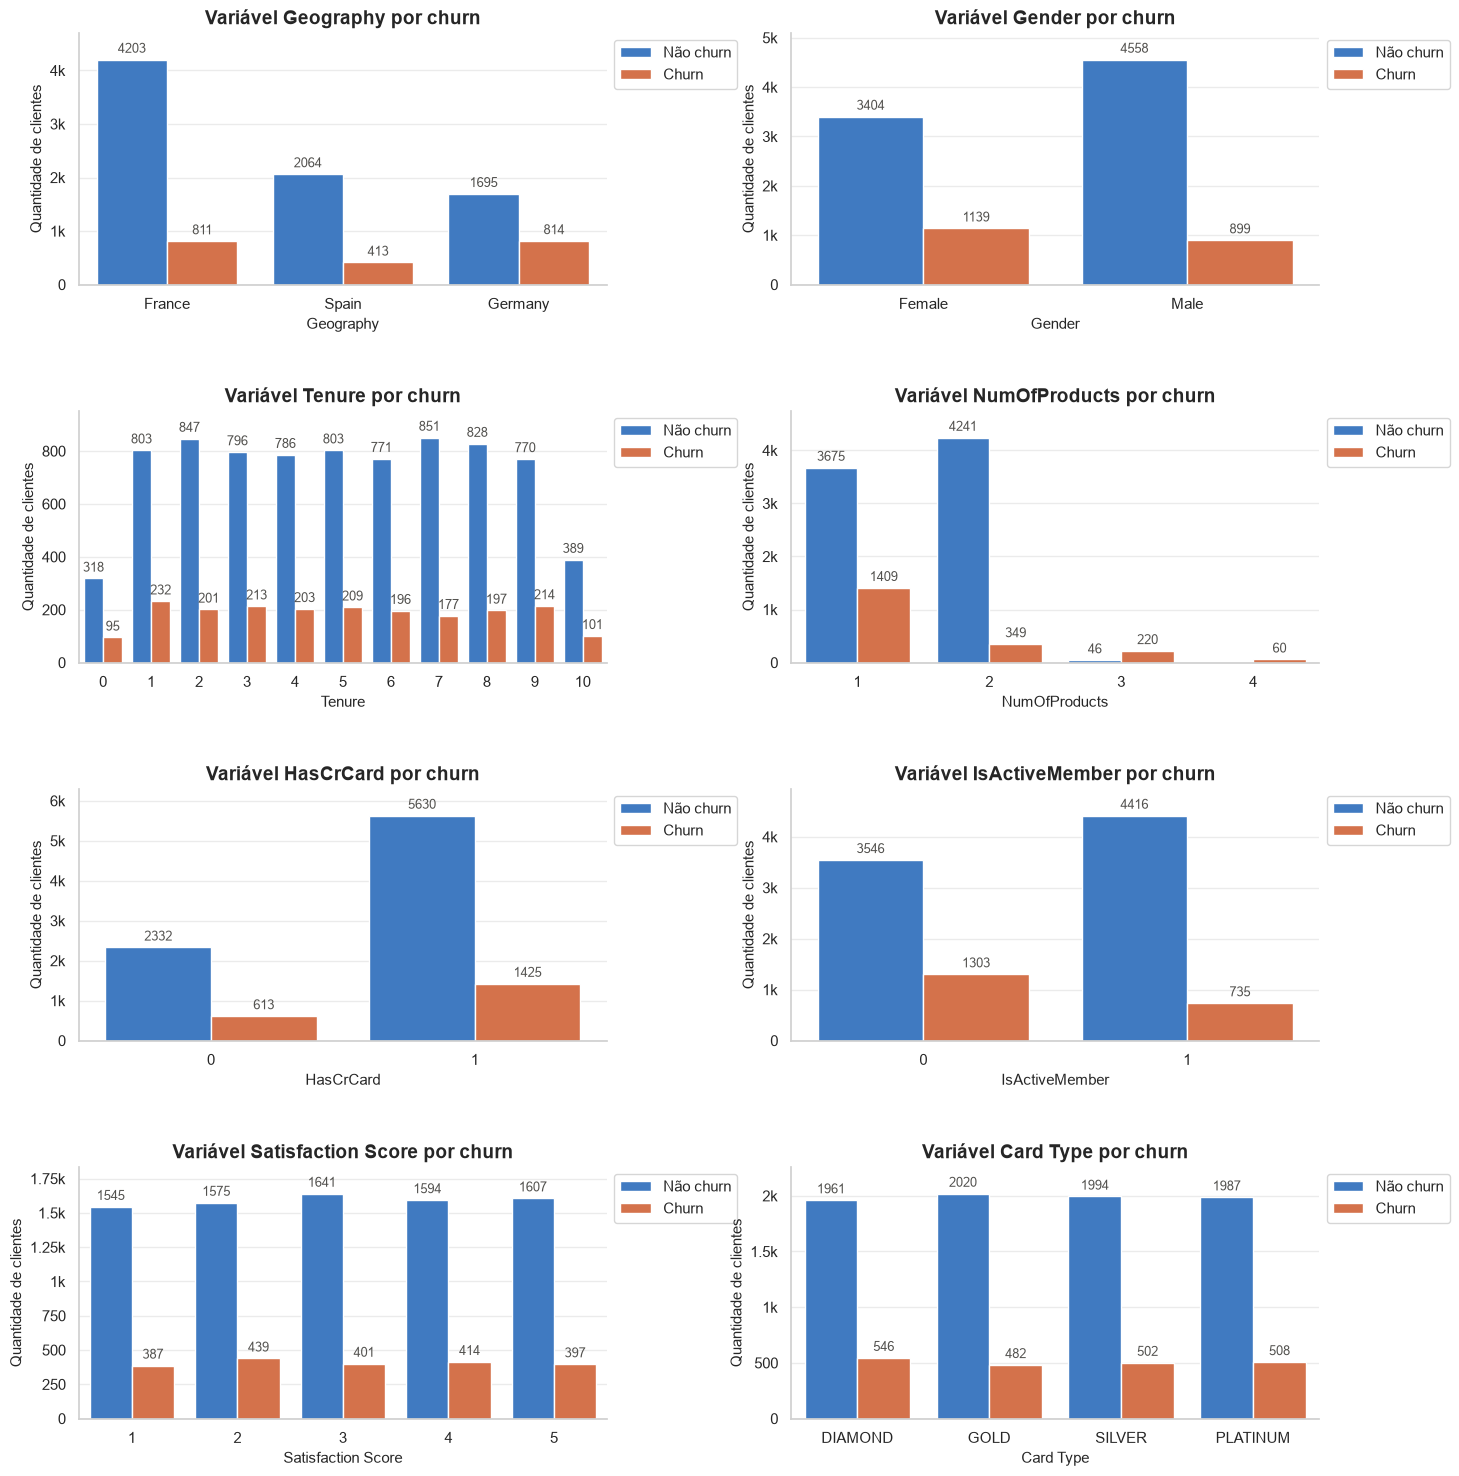

In [18]:
cols_bivariada = [col for col in cols_categoricas if col != 'Exited']

fig, axes = plt.subplots(4, 2, figsize=(16, 18))

for ax, col in zip(axes.flat, cols_bivariada):
    sns.countplot(x=col, hue='Exited', data=df, palette=PALETA_CHURN, ax=ax)
    ax.set_title(f'Variável {col} por churn')
    ax.set_ylabel('Quantidade de clientes')
    ax.yaxis.set_major_formatter(k_formatter)
    rotular_barras(ax, fontsize=9)
    handles, _ = ax.get_legend_handles_labels()
    ax.legend(handles, LEGENDA_CHURN, loc='upper left', bbox_to_anchor=(1, 1))  # Legenda fora do gráfico para não cobrir os números

plt.subplots_adjust(hspace=0.5, wspace=0.35)
plt.show()

Os gráficos de contagem mostram a quantidade de clientes, mas como as categorias têm tamanhos muito diferentes, fica difícil comparar a **proporção** de churn entre elas. Para isso, uso o mesmo gráfico de barras 100% empilhadas: cada barra mostra a divisão entre churn e não churn dentro da categoria, e a barra **Base toda** mostra o churn geral, para comparação.

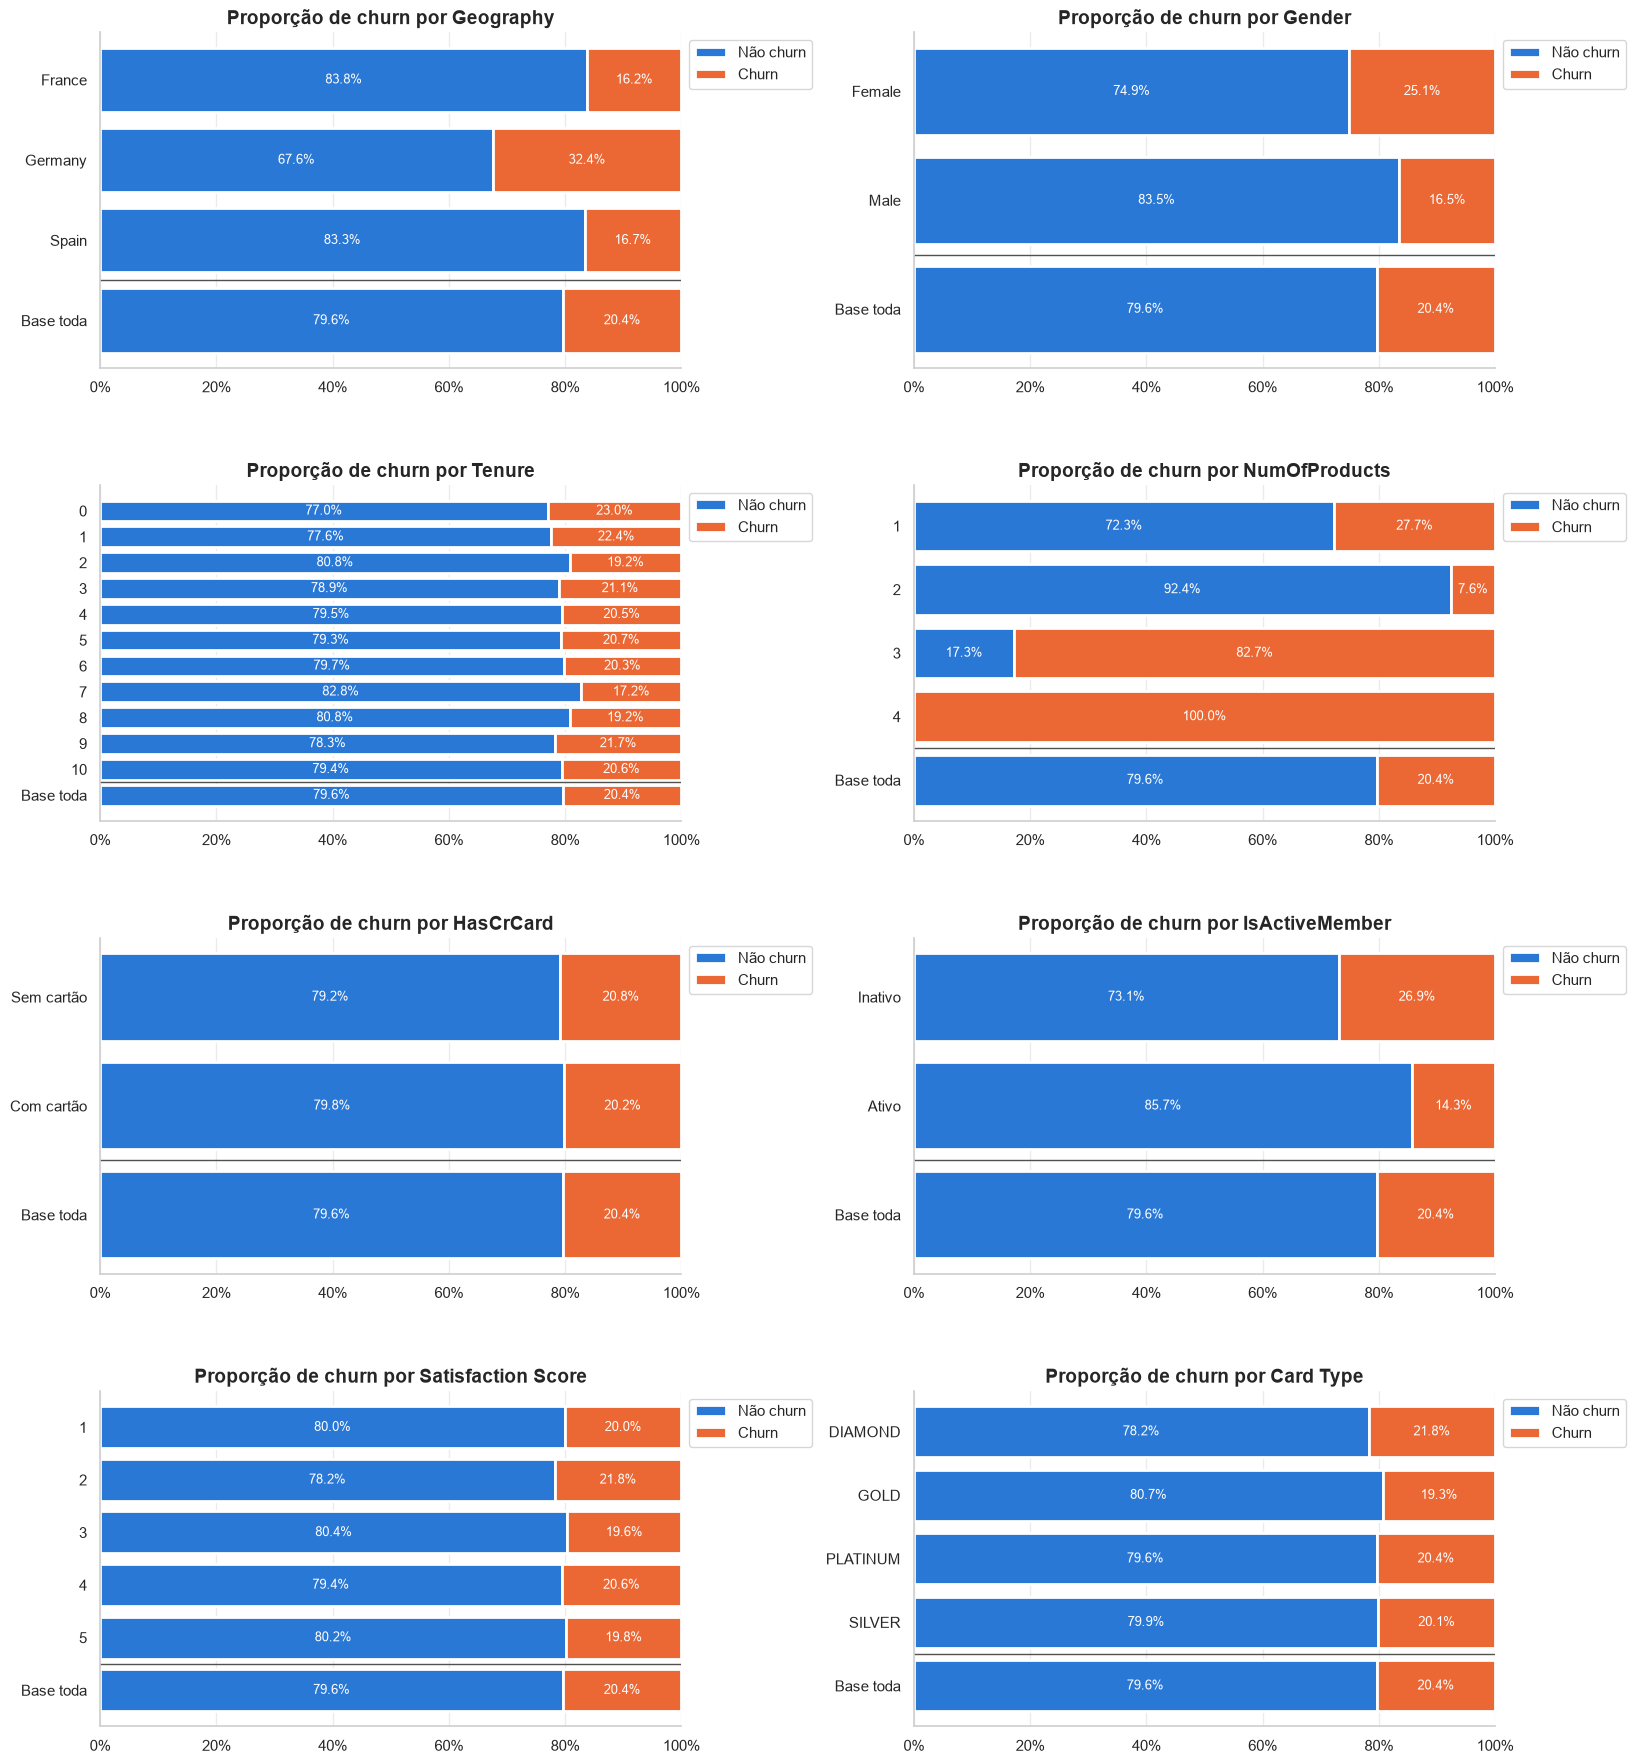

In [19]:
nomes_categorias = {    # rótulos mais claros para as variáveis binárias
    'HasCrCard': {0: 'Sem cartão', 1: 'Com cartão'},
    'IsActiveMember': {0: 'Inativo', 1: 'Ativo'},
}

fig, axes = plt.subplots(4, 2, figsize=(18, 22))

for ax, col in zip(axes.flat, cols_bivariada):
    rotulo = nomes_categorias[col].get if col in nomes_categorias else str
    barras_100(ax, df, col, 'Exited', [PALETA_CHURN[0], PALETA_CHURN[1]], dict(zip([0, 1], LEGENDA_CHURN)), rotulo_grupo=rotulo)
    ax.set_title(f'Proporção de churn por {col}')

plt.subplots_adjust(hspace=0.35, wspace=0.4)
plt.show()

Nos gráficos é possível observar a diferença agressiva na taxa de churn entre as categorias de número de produtos. Com esses valores surgem perguntas importantes de serem respondidas para negócio: o que faz clientes com mais de 2 produtos churnarem tanto? Porque os clientes com 2 produtos churnam cerca de **quatro vezes menos** que clientes com 1 produto? 

Por conta da variável de número de produtos ser tão determinante para saber se um cliente pode ter churn ou não, vou realizar uma pequena análise sobre essa variável posteriormente.

Outro detalhe importante de lembrar é que apesar do heatmap não mostrar correlação nenhuma entre o churn e o número de produtos (-0.05), essa é a variável com maior relação com o churn dos clientes. Isso acontece pelo forte desbalanceamento dentro dessa variável e pela relação não linear com o churn. Isso mostra que uma correlação próxima de zero no heatmap não significa que a variável é irrelevante.

**Insights:**
- A Alemanha tem o **dobro** de taxa de churn em comparação com os outros dois países, sendo essa taxa 32%;
- O número de produtos do cliente pode ser determinante para saber se ele vai churnar ou não. **Todos** clientes com 4 produtos churnaram e **mais de 80%** dos clientes com 3 produtos churnaram. Porém esses grupos são pequenos (60 e 266 clientes, 3.26% da base): em volume, a maior parte do churn está nos clientes com 1 produto (1409 dos 2038 churns, cerca de 69%);
- Clientes inativos churnam **26.9%**, quase o **dobro** dos clientes ativos (14.3%);
- As mulheres churnam **25.1%**, contra 16.5% dos homens;
- `Tenure`, `HasCrCard`, `Card Type` e `Satisfaction Score` têm a taxa de churn praticamente igual em todas as categorias. Chama atenção a `Satisfaction Score`: mesmo sendo uma nota de satisfação, ela não tem relação nenhuma com o churn.

### Variáveis Contínuas

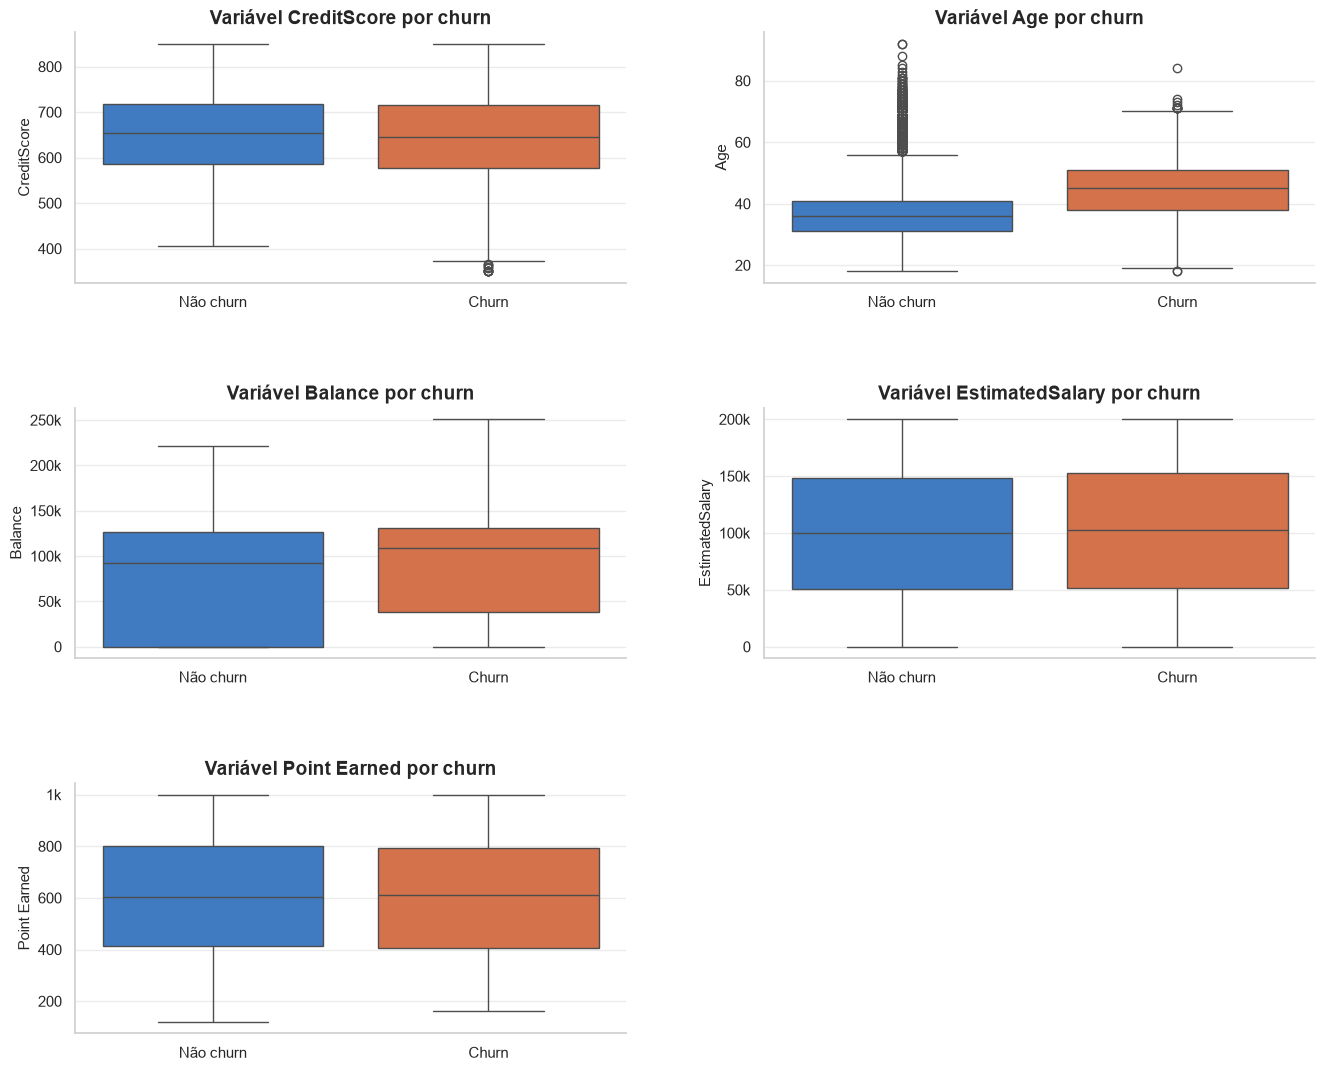

In [20]:
fig, axes = plt.subplots(3, 2, figsize=(16, 13))

for ax, col in zip(axes.flat, cols_continuas):
    sns.boxplot(x='Exited', y=col, hue='Exited', data=df, palette=PALETA_CHURN, legend=False, ax=ax)
    ax.set_xticks([0, 1], LEGENDA_CHURN)
    ax.set_xlabel('')
    ax.set_title(f'Variável {col} por churn')
    ax.yaxis.set_major_formatter(k_formatter)

axes.flat[-1].remove()   # 5 gráficos em uma grade 3x2: remove o espaço que sobra

plt.subplots_adjust(hspace=0.5, wspace=0.25)
plt.show()

Entre as variáveis contínuas, `Age` é a que apresenta a diferença mais clara entre churn e não-churn, com uma tendência de idades maiores churnarem mais. `Balance` mostra uma diferença menor (a mediana do saldo é mais alta entre quem churna), mas o boxplot mistura os clientes com saldo zero com os demais, então vou analisá-la separadamente depois de `Age`. `CreditScore`, `EstimatedSalary` e `Point Earned` não mostram diferença.

In [21]:
df[df['Exited'] == 1]['Age'].mean() - df[df['Exited'] == 0]['Age'].mean()

np.float64(7.427559859282525)

A diferença da média de idade entre os clientes que churnam e os que não churnam é de 7 anos, ou seja, em média os clientes que churnam são **7 anos mais velhos** que os outros.

Como a média sozinha esconde a forma da relação, vou olhar a taxa de churn em cada faixa etária.

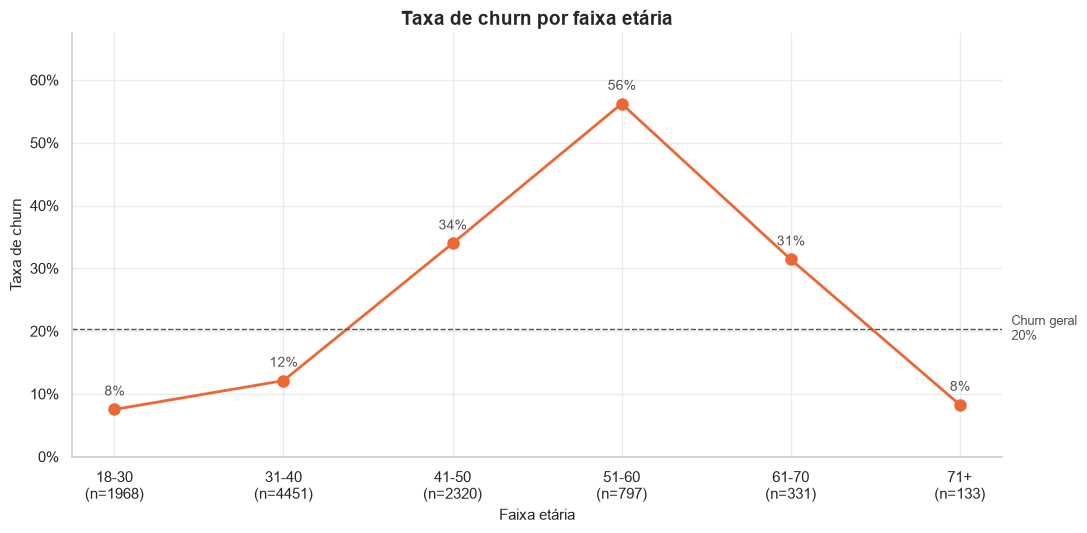

In [22]:
faixa_etaria = pd.cut(df['Age'], bins=[17, 30, 40, 50, 60, 70, 92],
                      labels=['18-30', '31-40', '41-50', '51-60', '61-70', '71+'])
churn_faixa = df.groupby(faixa_etaria, observed=True)['Exited'].agg(['mean', 'size'])
churn_geral = df['Exited'].mean()

fig, ax = plt.subplots(figsize=(12, 5.5))
x = range(len(churn_faixa))
ax.plot(x, churn_faixa['mean'], color=PALETA_CHURN[1], linewidth=2, marker='o', markersize=8)
for xi, taxa in zip(x, churn_faixa['mean']):     # Escreve a taxa em cima de cada ponto
    ax.annotate(f'{taxa:.0%}', (xi, taxa), textcoords='offset points', xytext=(0, 10), ha='center', fontsize=10, color=COR_REFERENCIA)
ax.set_ylim(0, churn_faixa['mean'].max() * 1.2)
linha_referencia(ax, churn_geral, f'Churn geral\n{churn_geral:.0%}')
ax.set_xticks(range(len(churn_faixa)), [f'{faixa}\n(n={n})' for faixa, n in churn_faixa['size'].items()])   # quantidade de clientes em cada faixa
ax.yaxis.set_major_formatter(ticker.PercentFormatter(1, decimals=0))
ax.set_title('Taxa de churn por faixa etária')
ax.set_xlabel('Faixa etária')
ax.set_ylabel('Taxa de churn')
fig.savefig(PASTA_FIGURAS / 'churn_por_faixa_etaria.png', dpi=150, bbox_inches='tight')   # usada no README
plt.show()

A relação entre idade e churn **não é totalmente linear**: a taxa sobe de 8% (18-30 anos) até **56% na faixa de 51-60 anos**, mais que o dobro do churn geral, e depois volta a cair, chegando a 8% entre os clientes com mais de 70 anos.

Ou seja, "quanto mais velho, mais churn" só vale até os 60 anos. Isso também confirma que os outliers de idade (acima de 62 anos) não são clientes de alto risco: eles churnam menos que a faixa de 41-60 anos.

Agora a variável `Balance`. Na univariada vimos que 36% dos clientes têm saldo zero, e o boxplot acima mistura esses clientes com os demais. Vou separar os dois grupos para comparar a taxa de churn e também ver **quem são** os clientes com saldo zero.

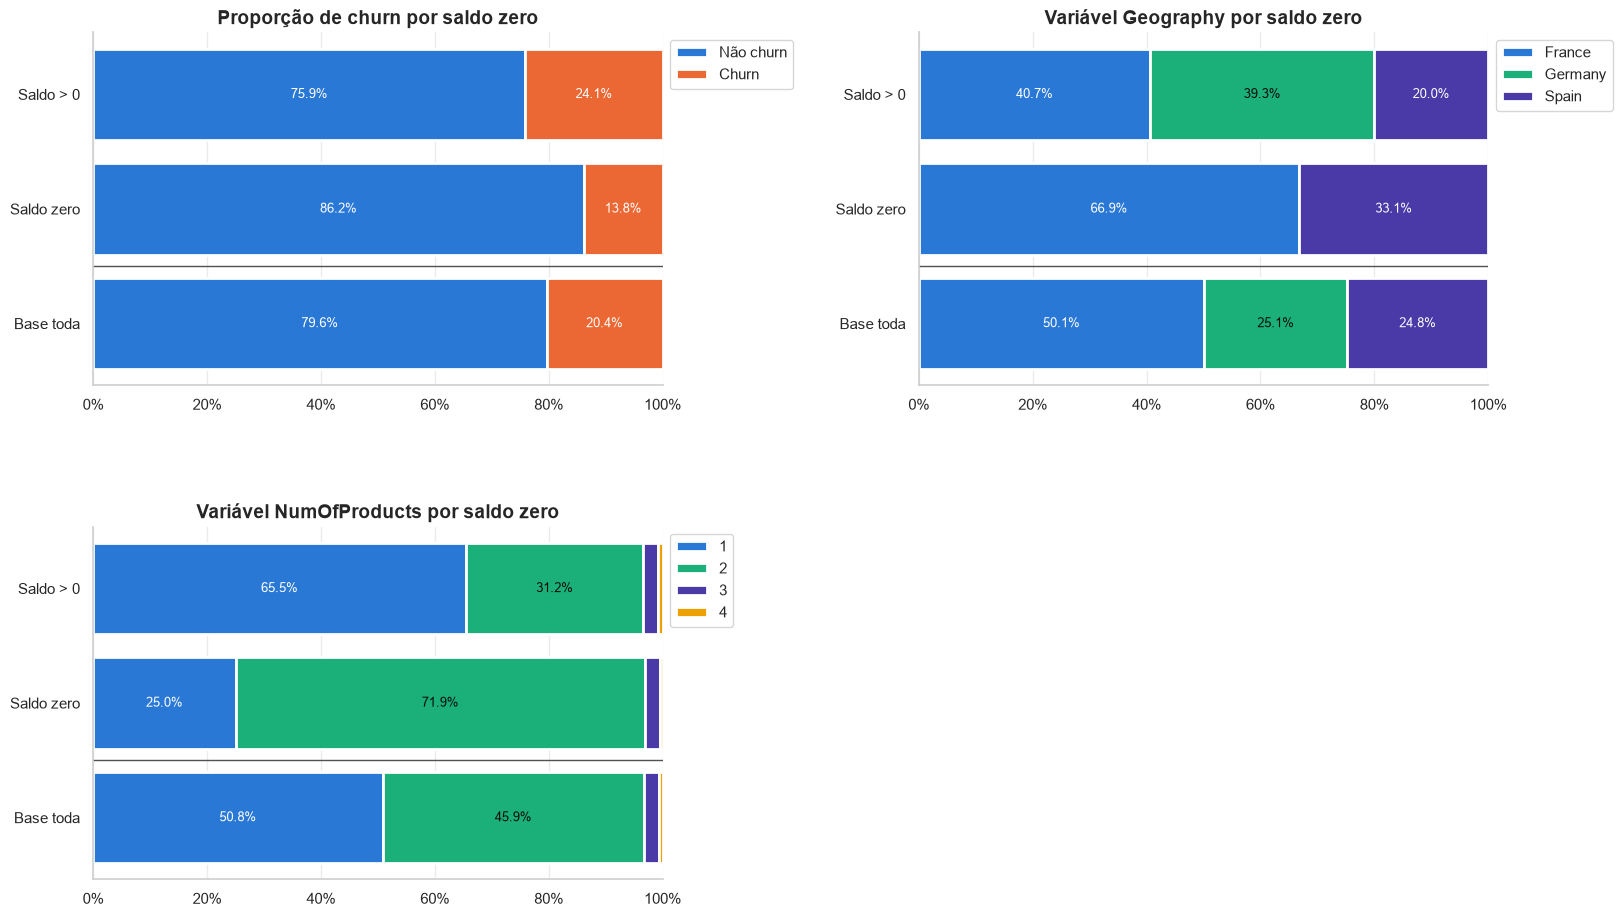

In [23]:
saldo = df.assign(**{'Saldo zero': df['Balance'] == 0})   # coluna auxiliar só para a análise de saldo, o df não muda
nomes_saldo = {False: 'Saldo > 0', True: 'Saldo zero'}

fig, axes = plt.subplots(2, 2, figsize=(18, 11))

barras_100(axes[0, 0], saldo, 'Saldo zero', 'Exited', [PALETA_CHURN[0], PALETA_CHURN[1]], dict(zip([0, 1], LEGENDA_CHURN)),
           rotulo_grupo=nomes_saldo.get)
axes[0, 0].set_title('Proporção de churn por saldo zero')

for ax, col in zip([axes[0, 1], axes[1, 0]], ['Geography', 'NumOfProducts']):   # perfil de cada grupo de saldo
    barras_100(ax, saldo, 'Saldo zero', col, PALETA_CATEGORIAS, rotulo_grupo=nomes_saldo.get)
    ax.set_title(f'Variável {col} por saldo zero')

axes[1, 1].remove()   # 3 gráficos em uma grade 2x2: remove o espaço que sobra

plt.subplots_adjust(hspace=0.4, wspace=0.45)
plt.show()

**Insights:**
- Clientes com saldo zero churnam **13.8%**, contra **24.1%** dos clientes com saldo;
- A **Alemanha não tem nenhum cliente com saldo zero**: eles estão todos na França (67%) e na Espanha (33%);
- 72% dos clientes com saldo zero têm 2 produtos, o grupo que menos churna.

Ou seja, o grupo de saldo zero é formado justamente por perfis de baixo churn. Para saber se a diferença vem do saldo ou do país, vou comparar a taxa de churn dentro de cada país.

In [24]:
churn_pais_saldo = saldo.pivot_table(index='Geography', columns='Saldo zero', values='Exited', aggfunc='mean') * 100
churn_pais_saldo.rename(columns=nomes_saldo).rename_axis(columns=None).round(1)   # taxa de churn (%); a Alemanha não tem clientes com saldo zero

,Saldo > 0,Saldo zero
Geography,,
France,18.3,13.9
Germany,32.4,NaN
Spain,19.6,13.6


Dentro da França e da Espanha a diferença é menor (cerca de 14% com saldo zero contra 18-20% com saldo), e a Alemanha churna 32% mesmo comparando só clientes com saldo. Com isso:
- O churn alto da Alemanha **não é explicado pelo saldo**;
- Boa parte da correlação de `Balance` com o churn (0.12) vem da composição dos grupos: os clientes com saldo zero estão fora da Alemanha e concentrados no grupo de 2 produtos. O saldo zero funciona mais como um **marcador de perfil** do que como causa do churn.

### Análise de `NumOfProducts`

A análise bivariada mostrou que `NumOfProducts` é a variável que mais separa os clientes que churnam dos que não churnam. Nesta seção vou fazer com ela a mesma análise bivariada que fiz com a target: comparar como as outras variáveis se distribuem em cada grupo de número de produtos, para entender o perfil de cada grupo.

No heatmap do início da análise, `NumOfProducts` só tem correlação relevante com `Balance` (-0.30). Vou entender de onde ela vem na parte de variáveis contínuas.

#### Variáveis Categóricas

Cada barra mostra como os clientes de um grupo se dividem entre as categorias da variável. A barra **Base toda**, embaixo, serve de referência: quando um grupo foge muito dela, ele tem um perfil diferente da média dos clientes.

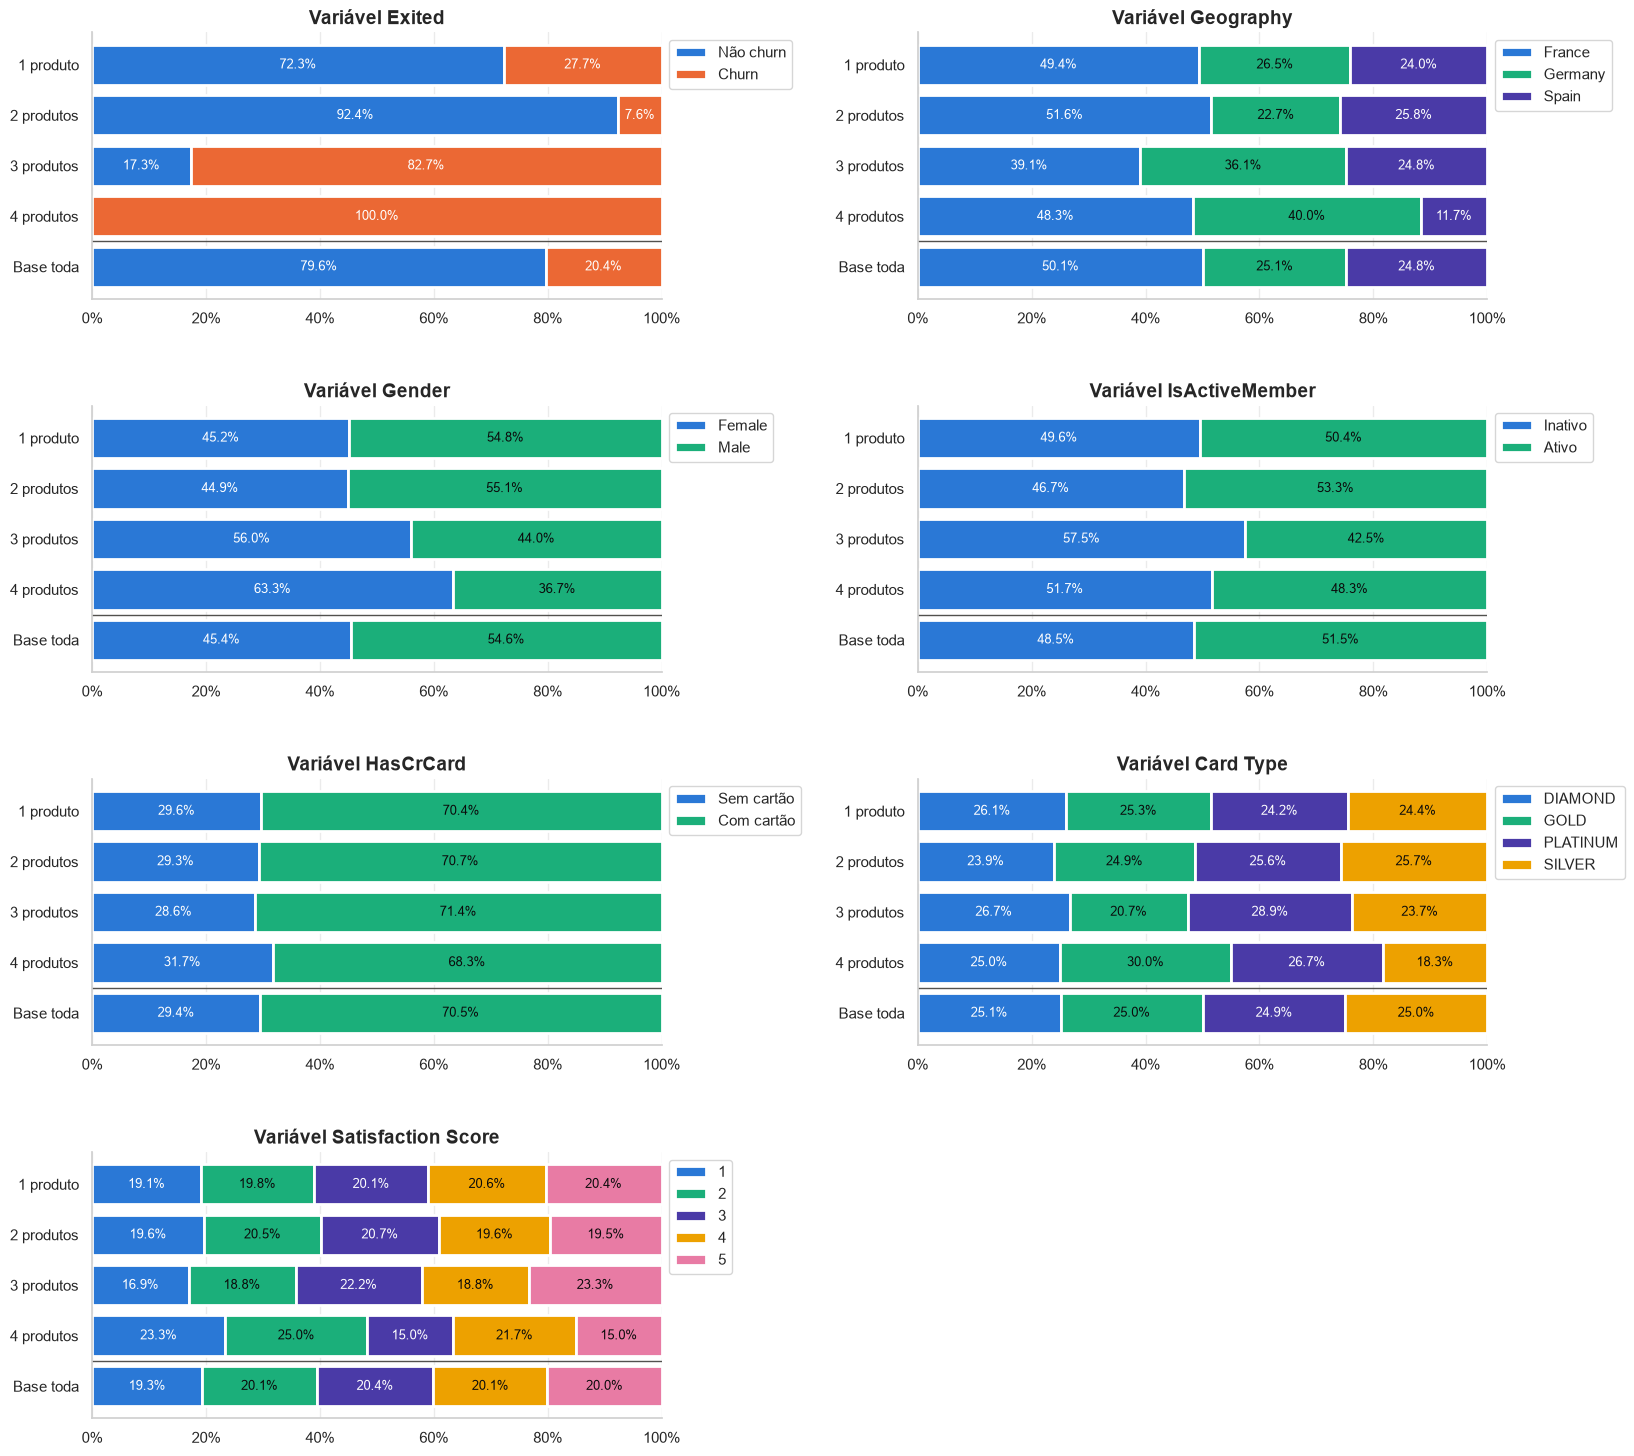

In [25]:
def nome_produtos(p):     # 1 -> "1 produto", 2 -> "2 produtos"
    return f'{p} produto' + ('s' if p > 1 else '')

graficos = [
    ('Exited', [PALETA_CHURN[0], PALETA_CHURN[1]], dict(zip([0, 1], LEGENDA_CHURN))),
    ('Geography', PALETA_CATEGORIAS, None),
    ('Gender', PALETA_CATEGORIAS, None),
    ('IsActiveMember', PALETA_CATEGORIAS, {0: 'Inativo', 1: 'Ativo'}),
    ('HasCrCard', PALETA_CATEGORIAS, {0: 'Sem cartão', 1: 'Com cartão'}),
    ('Card Type', PALETA_CATEGORIAS, None),
    ('Satisfaction Score', PALETA_CATEGORIAS, None),
]

fig, axes = plt.subplots(4, 2, figsize=(18, 18))

for ax, (col, cores, nomes) in zip(axes.flat, graficos):
    barras_100(ax, df, 'NumOfProducts', col, cores, nomes, rotulo_grupo=nome_produtos)

axes.flat[-1].remove()   # 7 gráficos em uma grade 4x2: remove o espaço que sobra

plt.subplots_adjust(hspace=0.4, wspace=0.45)
plt.show()

**Insights:**
- `Geography` : os grupos de 3 e 4 produtos têm **mais clientes da Alemanha** (36% e 40%, contra 25% na base toda), o país com a maior taxa de churn.
- `Gender` : os grupos de 3 e 4 produtos têm **mais mulheres** (56% e 63%, contra 45% na base toda), o gênero que churna mais.

Ou seja, os grupos de 3 e 4 produtos concentram perfis que já churnam mais (Alemanha, mulheres). Isso ajuda a explicar parte do churn mais elevado desses grupos.

#### Variáveis Contínuas

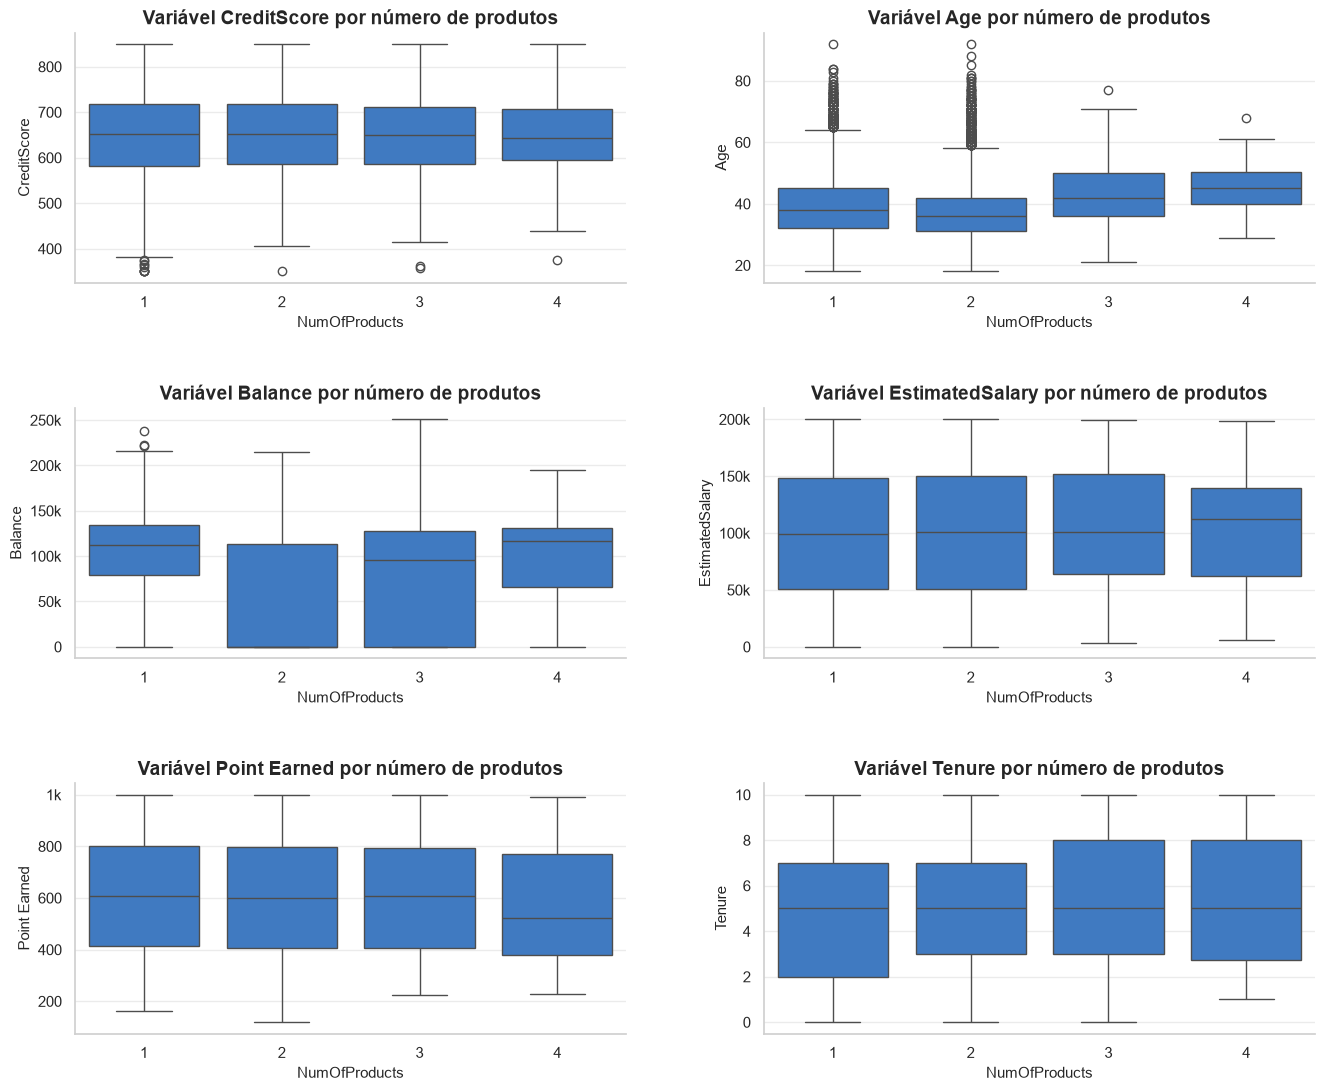

In [26]:
fig, axes = plt.subplots(3, 2, figsize=(16, 13))

for ax, col in zip(axes.flat, cols_continuas + ['Tenure']):
    sns.boxplot(x='NumOfProducts', y=col, data=df, color=COR_PRINCIPAL, ax=ax)
    ax.set_title(f'Variável {col} por número de produtos')
    ax.yaxis.set_major_formatter(k_formatter)

plt.subplots_adjust(hspace=0.5, wspace=0.25)
plt.show()

Percebi que alguns boxplots da variável balance mostram uma tendência de saldo muito baixo. Vou verificar a proporção de contas zeradas em cada grupo de produtos para entender como está distribuída a enorme quantidade de contas zeradas identificadas no começo da análise. Isso vai confirmar se são essas contas zeradas que causaram esse efeito.

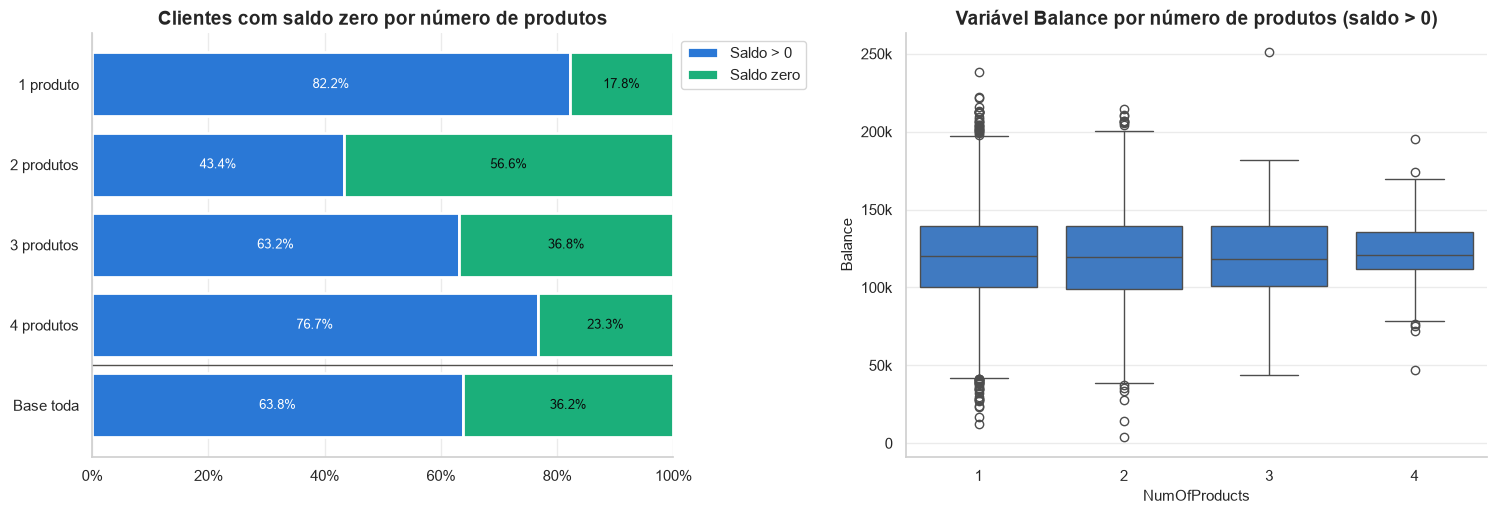

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5.5))

barras_100(axes[0], saldo, 'NumOfProducts', 'Saldo zero', [PALETA_CATEGORIAS[0], PALETA_CATEGORIAS[1]],
           {False: 'Saldo > 0', True: 'Saldo zero'}, rotulo_grupo=nome_produtos)
axes[0].set_title('Clientes com saldo zero por número de produtos')

sns.boxplot(x='NumOfProducts', y='Balance', data=saldo[~saldo['Saldo zero']], color=COR_PRINCIPAL, ax=axes[1])
axes[1].set_title('Variável Balance por número de produtos (saldo > 0)')
axes[1].yaxis.set_major_formatter(k_formatter)

plt.subplots_adjust(wspace=0.4)
plt.show()

Como visto no boxplot sem as contas zeradas, entre os clientes que têm saldo ele é praticamente igual em todos os grupos de produtos. A correlação de -0.30 vem apenas da quantidade de contas zeradas em cada grupo.

Percebi também uma leve diferença entre as idades, vou verificar a mediana das idades em cada grupo.

In [28]:
for i in range(1, 5):
    print(f"Mediana da idade para {i} produto(s): {df[df['NumOfProducts'] == i]['Age'].median():.0f}")

Mediana da idade para 1 produto(s): 38
Mediana da idade para 2 produto(s): 36
Mediana da idade para 3 produto(s): 42
Mediana da idade para 4 produto(s): 45


**Insights:**
- `Age`: os grupos de 3 e 4 produtos são **mais velhos** (mediana de 42 e 45 anos, contra 36-38 nos grupos de 1 e 2 produtos), outra característica associada a mais churn;
- `Balance`: o grupo de 2 produtos tem a mediana do saldo em **zero**, porque a maioria desses clientes (57%) está com a conta zerada. Entre os clientes que têm saldo, ele é parecido em todos os grupos. É isso que gera a correlação de -0.30 que aparece no heatmap;
- `CreditScore`, `EstimatedSalary`, `Point Earned` e `Tenure` são praticamente iguais entre os grupos.

# Resumo

Antes da análise, removi a variável `Complain`, que tem 99.6% de correlação com o churn (vazamento de dados). A variável alvo está desbalanceada: **20%** dos clientes churnam, o que precisa ser tratado na modelagem.

Cinco variáveis mostram relação clara com o churn:

- `NumOfProducts`: a mais determinante. Clientes com 2 produtos churnam **7.6%**, quase **4x menos** que os com 1 produto (27.7%). Já **mais de 80%** dos clientes com 3 produtos e **todos** com 4 produtos churnaram, mas esses dois grupos somam só 3.26% da base. Em volume, 69% do churn está nos clientes com 1 produto.
- `Age`: em média quem churna é **7 anos mais velho**, mas a relação não é linear: o churn sobe de 8% (18-30) até **56% (51-60)** e volta a cair para 8% acima dos 70.
- `Geography`: a Alemanha tem o **dobro** da taxa de churn dos outros países (32% contra ~16%), e isso não é explicado pelo saldo.
- `IsActiveMember`: inativos churnam **26.9%**, quase o dobro dos ativos (14.3%).
- `Gender`: mulheres churnam **25.1%**, contra 16.5% dos homens.

`Balance` parece ter relação com o churn (clientes com saldo zero churnam 13.8%, contra 24.1% dos com saldo), mas boa parte dessa diferença vem da composição do grupo: **nenhum cliente da Alemanha tem saldo zero**, e 72% dos clientes com saldo zero têm 2 produtos. O saldo zero funciona mais como marcador de perfil do que como causa do churn.

Na análise de `NumOfProducts`, os grupos de 3 e 4 produtos concentram os perfis de maior risco (Alemanha, mulheres e clientes mais velhos), o que explica parte do churn elevado desses grupos. A variável quase não tem correlação linear com o churn no heatmap (-0.05), o que mostra que correlação perto de zero não quer dizer que a variável é irrelevante.

As demais variáveis (`CreditScore`, `EstimatedSalary`, `Point Earned`, `Tenure`, `HasCrCard`, `Card Type`, `Satisfaction Score`) não mostram diferença relevante entre quem churna e quem fica.

Com a análise feita, vou salvar o dataset tratado para a modelagem.

In [29]:
df.to_csv(DADOS_TRATADOS, index=False)